# Final image-only word verification — A, B and C

**Weights:** `real_abc_balanced_optional_space_20261108`. **All three books were trained:** A=1,107, B=1,107, C=1,107 lines. Figure captions distinguish each line’s membership from its book’s training exposure.

Strong long visual passages are retained. Short masks require matching whole-word hypotheses, full-line context and a full-span visual check. Predictions use images and a fixed training-only vocabulary; supplied line transcripts are not inference inputs.

| Book pair | Positive pairs | Mask IoU | Precision | Recall |
| --- | ---: | ---: | ---: | ---: |
| A–B | 23 | 72.08% | 75.87% | 89.19% |
| A–C | 4 | 54.24% | 64.70% | 62.76% |
| B–C | 2 | 54.91% | 93.07% | 56.90% |

Overall IoU **68.44%**, Dice **77.79%**, precision **75.52%**, recall **83.32%**. False detections: **15/100**. Test FPR exceeds the requested 10% budget.

29 saved-test positives + 100 presumed negatives; supplied cases and shared source images excluded. Validation selection weights the three book pairs equally and prioritizes foreground precision. Counts for C are small.

- `pair_000016__A_line_014__B_line_003`: **89.50% IoU**.
- `pair_000028__A_line_005__B_line_002`: **76.01% IoU**.

**Masks and word identities are predictions. Unknown vocabulary and repeated words remain limitations.** The local C text files are concatenated; original HPC training-text whitespace is unverified. This does not mean C was untrained.

[Full current report](../docs/word_alignment_evaluation.md) · [All metrics](../docs/evaluation/word_alignment_20261109/metrics.json) · [Per-pair scores](../docs/evaluation/word_alignment_20261109/per_pair.csv)

**Reopen the notebook from disk, then restart its kernel to load the edited configuration.**

# A–B, B–C and A–C qualitative review
15 selected examples: 5 per book pair.
Checkpoint: `Weights/real_abc_balanced_optional_space_20261108/checkpoint_best.pt`.
Saved training-line counts by book: A=1,107, B=1,107, C=1,107. Line membership below refers to the individual image, not whether its book was trained.
Matching parameters from `Results/Evaluation/word_alignment_20261109/word_selected.json`; representation=`fused`, crop=`none`, device=`mps`.
Same fixed examples as the original review, selected using the previous checkpoint. They have not been selected or ranked using the current checkpoint. Current checkpoint split membership is recorded per sample, including training and validation lines. An individual line absent from the balanced split does not mean its book was absent from training. This mixed-split qualitative comparison is not a held-out performance estimate.
Examples are selected for agreement with the supplied masks on both lines.
Saved outputs come from `scripts/eval/review_book_pairs.py`; no training or parameter search.


In [ ]:
from pathlib import Path
import json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'evaluation_utils.py').is_file())
REVIEW = ROOT / 'Results/Evaluation/word_alignment_20261109/fixed_examples'
REPORT = json.loads((REVIEW / 'report.json').read_text())
print('Matching parameters from:', Path(REPORT['settings_source']['path']).relative_to(ROOT))
print(json.dumps(REPORT['settings'], indent=2))


Matching parameters from: Results/Evaluation/word_alignment_20261109/word_selected.json
{
  "similarity_mode": "letter_evidence",
  "decoder": "word_dtw",
  "threshold": 0.5,
  "contrast_margin": 0.05,
  "score_mode": "background",
  "min_windows": 3,
  "max_gap": 4,
  "gap_open": 0.5940936607241908,
  "gap_extend": 0.5826132317598225,
  "max_candidates": 512,
  "repeat_penalty": 0.2,
  "max_stretch": 3,
  "acceptance_offset": 0.1,
  "prior_floor": 0.0001,
  "alignment_mode": "word_dtw",
  "max_consecutive_repeats": 2,
  "min_distinct_windows_a": 3,
  "min_distinct_windows_b": 3,
  "min_matched_pairs": 4,
  "use_strong_start_anchor": false,
  "start_top_k": 3,
  "start_min_reward": null,
  "min_region_score": null,
  "min_mean_reward": 0.0,
  "min_path_density": 0.85,
  "max_repeat_fraction": null,
  "min_secondary_score_ratio": null,
  "window_match_temperature": 0.1,
  "window_match_min_cosine": 0.5,
  "window_match_reward_offset": 0.0,
  "word_vocabulary_path": "docs/evaluation/word

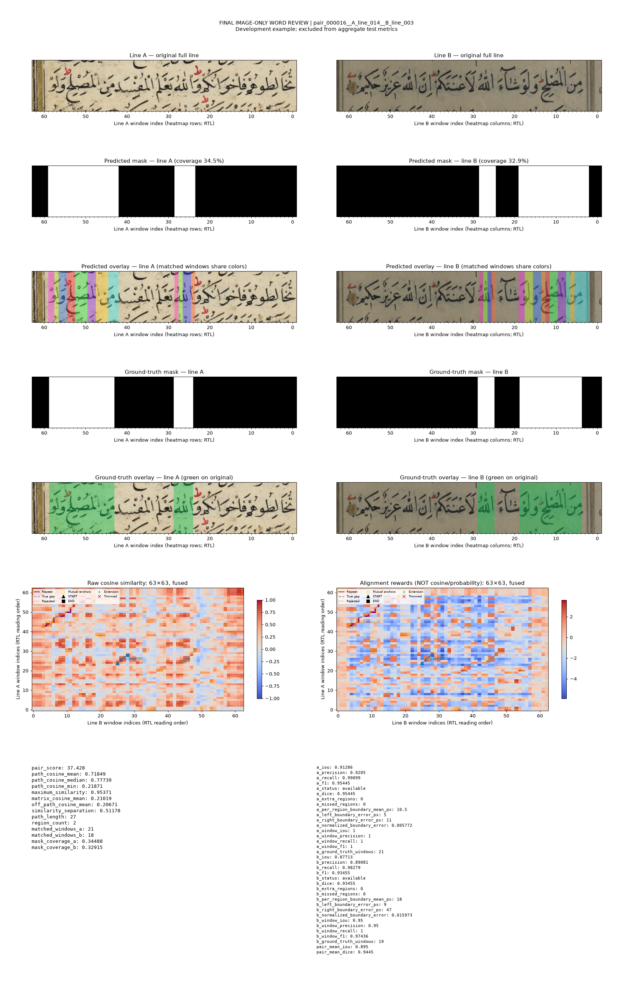

In [ ]:
from pathlib import Path
from IPython.display import Image, display
_word_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'word_alignment.py').is_file())
_word_figure = _word_root / 'Results/Evaluation/word_alignment_20261109/pair_000016__A_line_014__B_line_003_final.png'
print('Normalized word hypotheses:', ['الله'])
if _word_figure.is_file():
    display(Image(filename=str(_word_figure)))
else:
    print('Use the embedded final figure or regenerate with scripts/eval/render_word_review.py.')


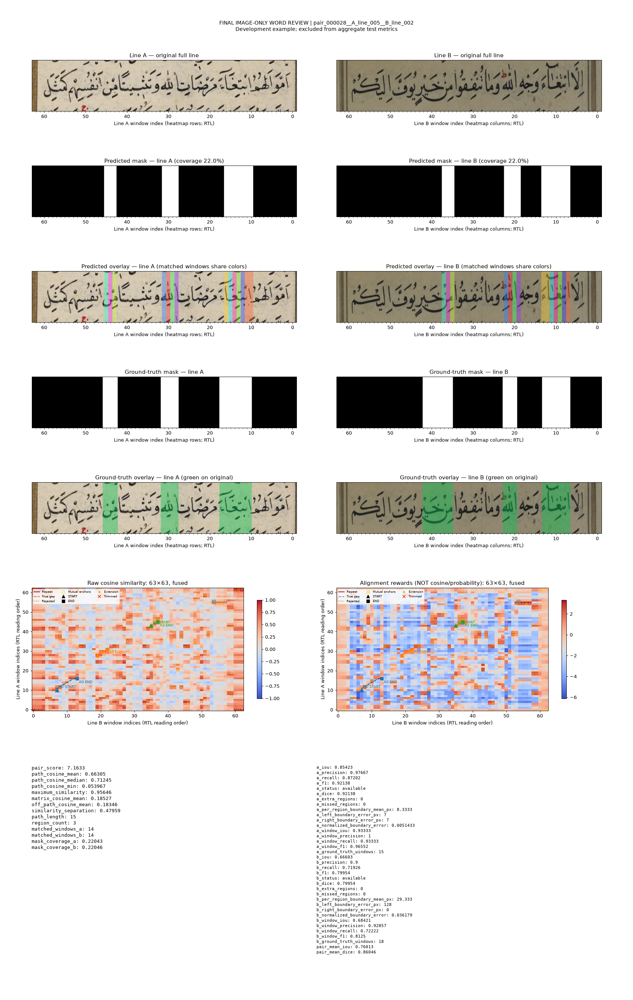

In [ ]:
from pathlib import Path
from IPython.display import Image, display
_word_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'word_alignment.py').is_file())
_word_figure = _word_root / 'Results/Evaluation/word_alignment_20261109/pair_000028__A_line_005__B_line_002_final.png'
print('Normalized word hypotheses:', ['ابتغا', 'الله', 'من'])
if _word_figure.is_file():
    display(Image(filename=str(_word_figure)))
else:
    print('Use the embedded final figure or regenerate with scripts/eval/render_word_review.py.')


A_B_example_01 | physical books A/B (plot rows A/B)
A: line=train; 1,107 book training lines | B: line=train; 1,107 book training lines
IoU: A=0.788, B=0.784; accepted routes=2
Mean mask IoU=0.786
White-mask precision: A=0.788, B=0.784; recall: A=1.000, B=1.000
Predicted white coverage: A=37.7%, B=37.6%
Black-background specificity: A=0.887, B=0.885
White F2 (recall priority): A=0.949, B=0.948


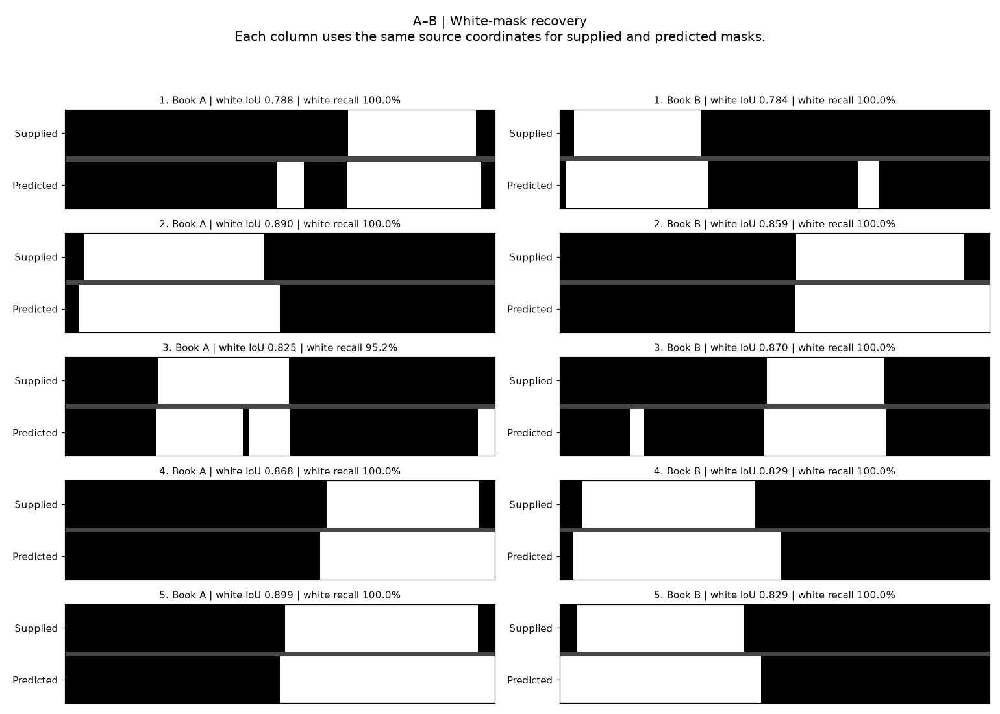

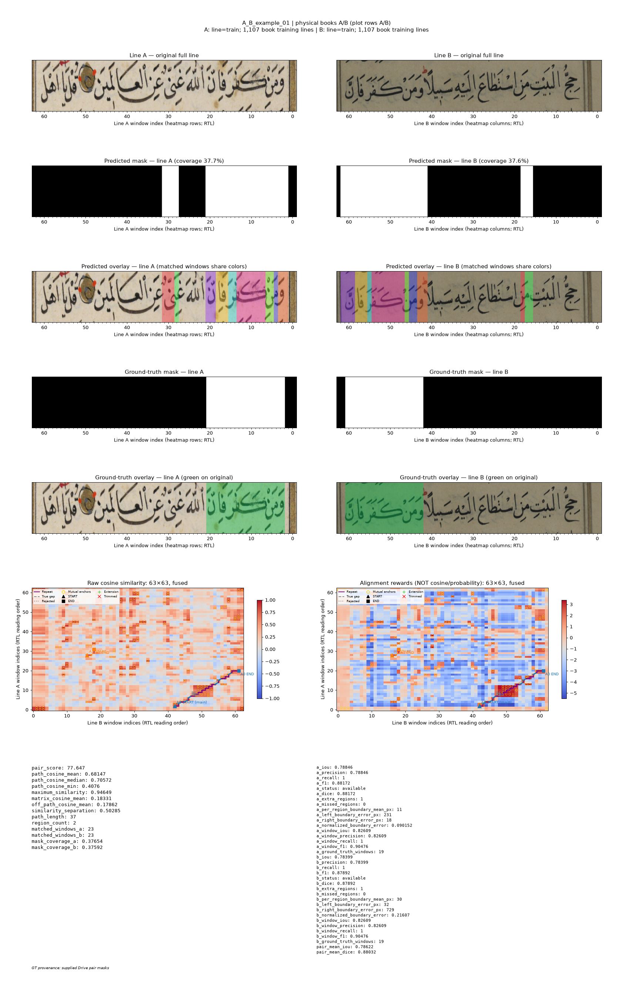

In [ ]:
from IPython.display import Image, display
print('A_B_example_01 | physical books A/B (plot rows A/B)\nA: line=train; 1,107 book training lines | B: line=train; 1,107 book training lines\nIoU: A=0.788, B=0.784; accepted routes=2\nMean mask IoU=0.786\nWhite-mask precision: A=0.788, B=0.784; recall: A=1.000, B=1.000\nPredicted white coverage: A=37.7%, B=37.6%\nBlack-background specificity: A=0.887, B=0.885\nWhite F2 (recall priority): A=0.949, B=0.948')
display(Image(filename=str(REVIEW / 'white_masks_A_B.png')))
display(Image(filename=str(REVIEW / 'A_B_example_01.png')))


A_B_example_02 | physical books A/B (plot rows A/B)
A: line=train; 1,107 book training lines | B: line=train; 1,107 book training lines
IoU: A=0.890, B=0.859; accepted routes=1
Mean mask IoU=0.874
White-mask precision: A=0.890, B=0.859; recall: A=1.000, B=1.000
Predicted white coverage: A=46.9%, B=45.3%
Black-background specificity: A=0.911, B=0.895
White F2 (recall priority): A=0.976, B=0.968


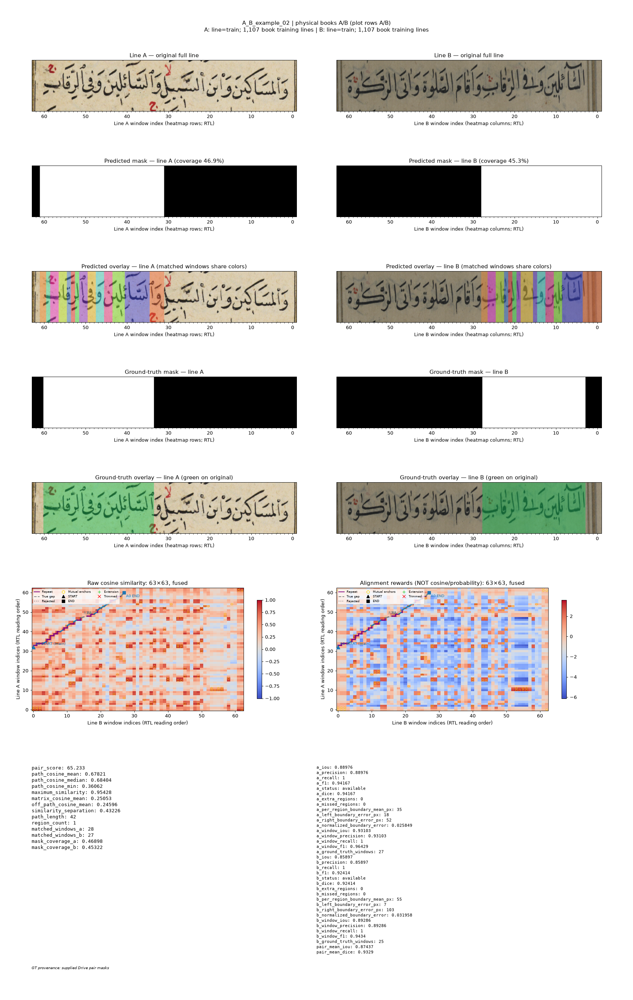

In [ ]:
from IPython.display import Image, display
print('A_B_example_02 | physical books A/B (plot rows A/B)\nA: line=train; 1,107 book training lines | B: line=train; 1,107 book training lines\nIoU: A=0.890, B=0.859; accepted routes=1\nMean mask IoU=0.874\nWhite-mask precision: A=0.890, B=0.859; recall: A=1.000, B=1.000\nPredicted white coverage: A=46.9%, B=45.3%\nBlack-background specificity: A=0.911, B=0.895\nWhite F2 (recall priority): A=0.976, B=0.968')
display(Image(filename=str(REVIEW / 'A_B_example_02.png')))


A_B_example_03 | physical books A/B (plot rows A/B)
A: line=train; 1,107 book training lines | B: line=train; 1,107 book training lines
IoU: A=0.825, B=0.870; accepted routes=3
Mean mask IoU=0.847
White-mask precision: A=0.861, B=0.870; recall: A=0.952, B=1.000
Predicted white coverage: A=33.8%, B=31.4%
Black-background specificity: A=0.932, B=0.944
White F2 (recall priority): A=0.932, B=0.971


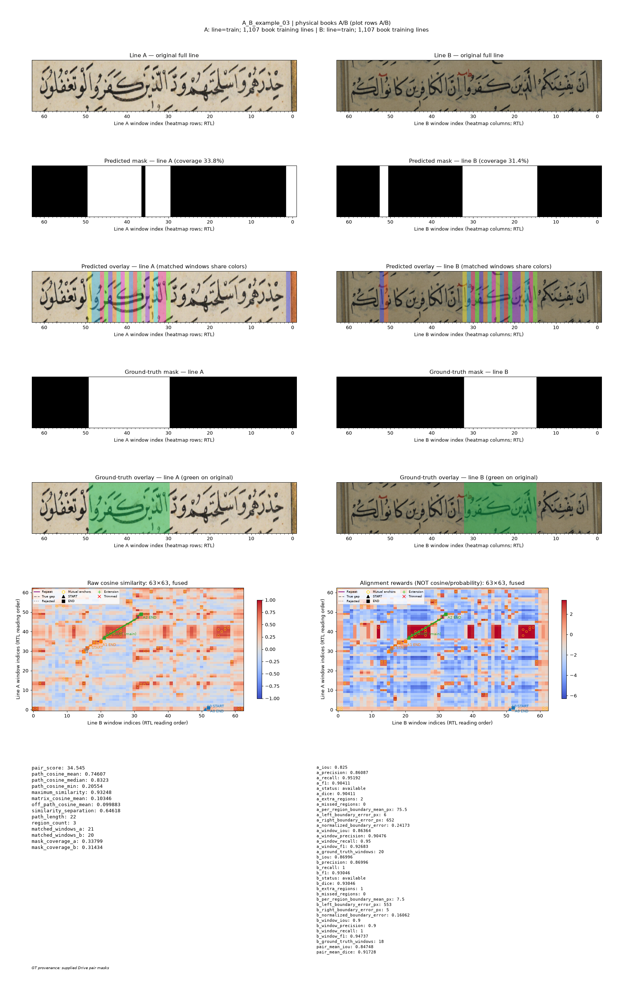

In [ ]:
from IPython.display import Image, display
print('A_B_example_03 | physical books A/B (plot rows A/B)\nA: line=train; 1,107 book training lines | B: line=train; 1,107 book training lines\nIoU: A=0.825, B=0.870; accepted routes=3\nMean mask IoU=0.847\nWhite-mask precision: A=0.861, B=0.870; recall: A=0.952, B=1.000\nPredicted white coverage: A=33.8%, B=31.4%\nBlack-background specificity: A=0.932, B=0.944\nWhite F2 (recall priority): A=0.932, B=0.971')
display(Image(filename=str(REVIEW / 'A_B_example_03.png')))


A_B_example_04 | physical books A/B (plot rows A/B)
A: line=outside saved subset; 1,107 book training lines | B: line=train; 1,107 book training lines
IoU: A=0.868, B=0.829; accepted routes=1
Mean mask IoU=0.848
White-mask precision: A=0.868, B=0.829; recall: A=1.000, B=1.000
Predicted white coverage: A=40.7%, B=48.5%
Black-background specificity: A=0.917, B=0.861
White F2 (recall priority): A=0.970, B=0.960


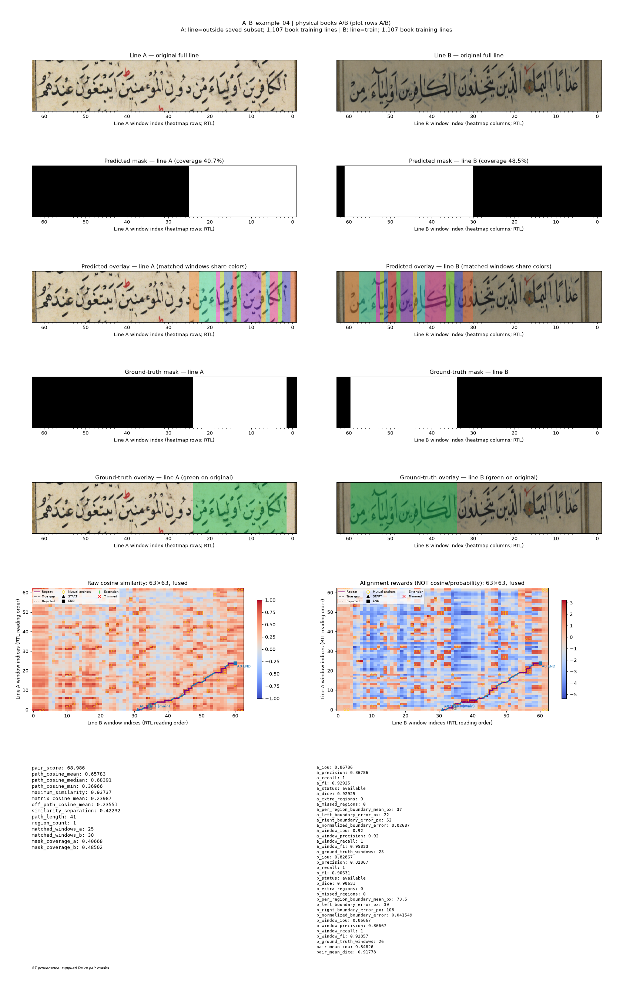

In [ ]:
from IPython.display import Image, display
print('A_B_example_04 | physical books A/B (plot rows A/B)\nA: line=outside saved subset; 1,107 book training lines | B: line=train; 1,107 book training lines\nIoU: A=0.868, B=0.829; accepted routes=1\nMean mask IoU=0.848\nWhite-mask precision: A=0.868, B=0.829; recall: A=1.000, B=1.000\nPredicted white coverage: A=40.7%, B=48.5%\nBlack-background specificity: A=0.917, B=0.861\nWhite F2 (recall priority): A=0.970, B=0.960')
display(Image(filename=str(REVIEW / 'A_B_example_04.png')))


A_B_example_05 | physical books A/B (plot rows A/B)
A: line=val; 1,107 book training lines | B: line=val; 1,107 book training lines
IoU: A=0.899, B=0.829; accepted routes=1
Mean mask IoU=0.864
White-mask precision: A=0.899, B=0.829; recall: A=1.000, B=1.000
Predicted white coverage: A=50.0%, B=46.9%
Black-background specificity: A=0.908, B=0.869
White F2 (recall priority): A=0.978, B=0.960


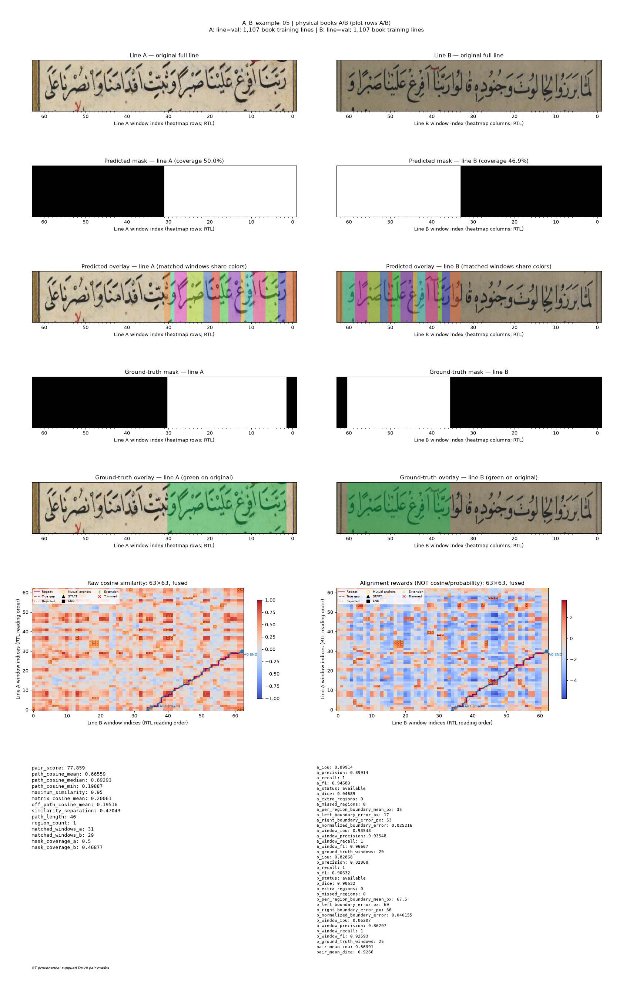

In [ ]:
from IPython.display import Image, display
print('A_B_example_05 | physical books A/B (plot rows A/B)\nA: line=val; 1,107 book training lines | B: line=val; 1,107 book training lines\nIoU: A=0.899, B=0.829; accepted routes=1\nMean mask IoU=0.864\nWhite-mask precision: A=0.899, B=0.829; recall: A=1.000, B=1.000\nPredicted white coverage: A=50.0%, B=46.9%\nBlack-background specificity: A=0.908, B=0.869\nWhite F2 (recall priority): A=0.978, B=0.960')
display(Image(filename=str(REVIEW / 'A_B_example_05.png')))


A_C_example_01 | physical books A/C (plot rows A/B)
A: line=outside saved subset; 1,107 book training lines | C: line=train; 1,107 book training lines
IoU: A=0.414, C=0.598; accepted routes=7
Mean mask IoU=0.506
White-mask precision: A=0.588, C=0.708; recall: A=0.583, C=0.794
Predicted white coverage: A=58.3%, C=84.5%
Black-background specificity: A=0.417, C=0.000
White F2 (recall priority): A=0.584, C=0.775


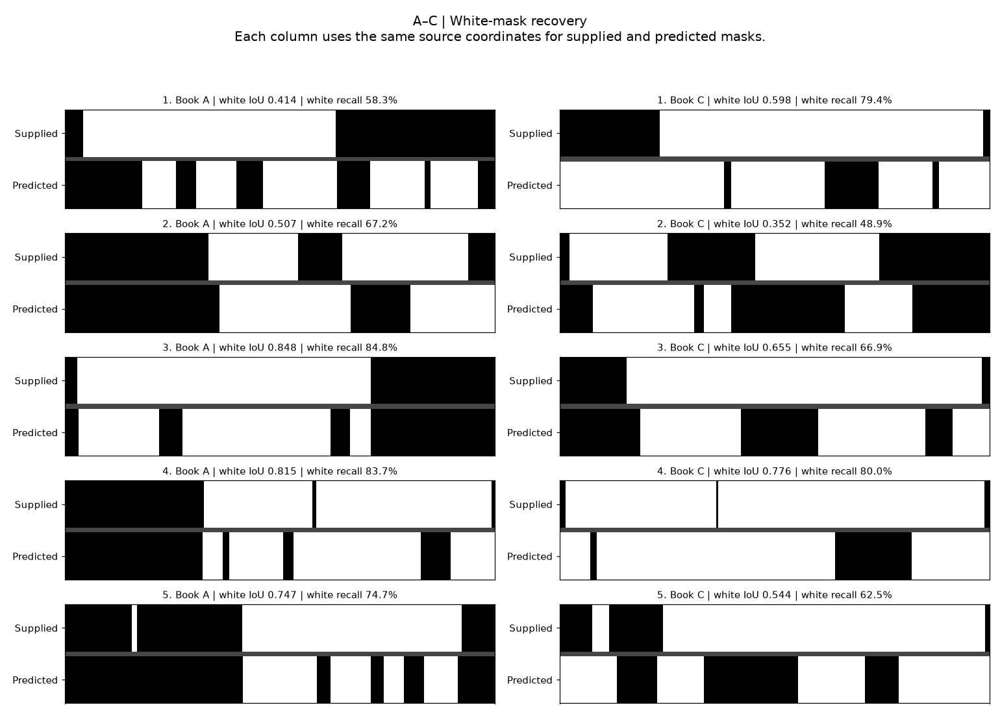

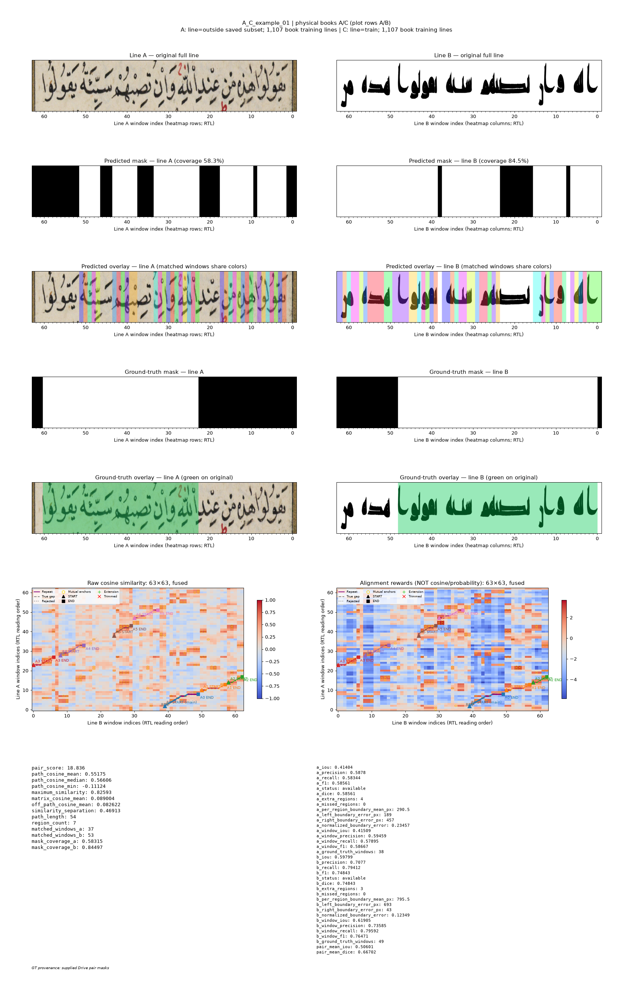

In [ ]:
from IPython.display import Image, display
print('A_C_example_01 | physical books A/C (plot rows A/B)\nA: line=outside saved subset; 1,107 book training lines | C: line=train; 1,107 book training lines\nIoU: A=0.414, C=0.598; accepted routes=7\nMean mask IoU=0.506\nWhite-mask precision: A=0.588, C=0.708; recall: A=0.583, C=0.794\nPredicted white coverage: A=58.3%, C=84.5%\nBlack-background specificity: A=0.417, C=0.000\nWhite F2 (recall priority): A=0.584, C=0.775')
display(Image(filename=str(REVIEW / 'white_masks_A_C.png')))
display(Image(filename=str(REVIEW / 'A_C_example_01.png')))


A_C_example_02 | physical books A/C (plot rows A/B)
A: line=outside saved subset; 1,107 book training lines | C: line=train; 1,107 book training lines
IoU: A=0.507, C=0.352; accepted routes=3
Mean mask IoU=0.429
White-mask precision: A=0.673, C=0.556; recall: A=0.672, C=0.489
Predicted white coverage: A=50.1%, C=45.4%
Black-background specificity: A=0.671, C=0.583
White F2 (recall priority): A=0.672, C=0.501


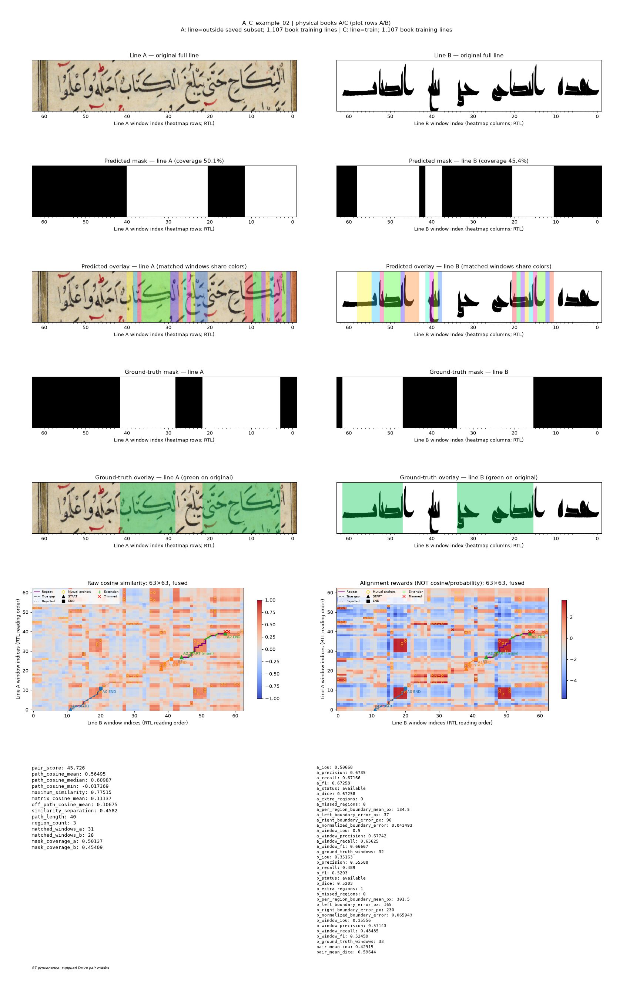

In [ ]:
from IPython.display import Image, display
print('A_C_example_02 | physical books A/C (plot rows A/B)\nA: line=outside saved subset; 1,107 book training lines | C: line=train; 1,107 book training lines\nIoU: A=0.507, C=0.352; accepted routes=3\nMean mask IoU=0.429\nWhite-mask precision: A=0.673, C=0.556; recall: A=0.672, C=0.489\nPredicted white coverage: A=50.1%, C=45.4%\nBlack-background specificity: A=0.671, C=0.583\nWhite F2 (recall priority): A=0.672, C=0.501')
display(Image(filename=str(REVIEW / 'A_C_example_02.png')))


A_C_example_03 | physical books A/C (plot rows A/B)
A: line=train; 1,107 book training lines | C: line=train; 1,107 book training lines
IoU: A=0.848, C=0.655; accepted routes=4
Mean mask IoU=0.752
White-mask precision: A=1.000, C=0.969; recall: A=0.848, C=0.669
Predicted white coverage: A=58.0%, C=57.1%
Black-background specificity: A=1.000, C=0.898
White F2 (recall priority): A=0.875, C=0.713


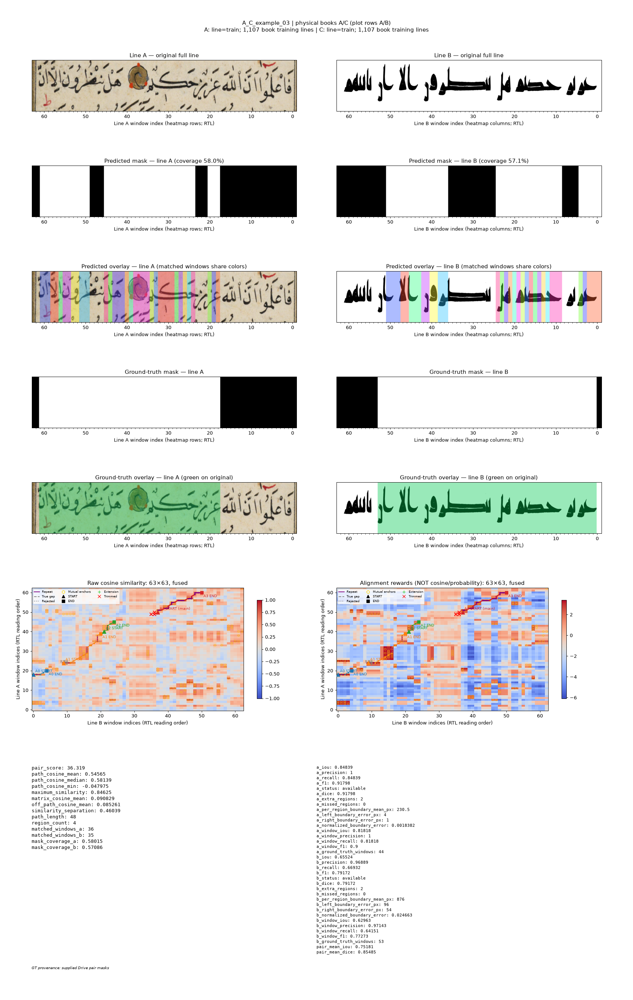

In [ ]:
from IPython.display import Image, display
print('A_C_example_03 | physical books A/C (plot rows A/B)\nA: line=train; 1,107 book training lines | C: line=train; 1,107 book training lines\nIoU: A=0.848, C=0.655; accepted routes=4\nMean mask IoU=0.752\nWhite-mask precision: A=1.000, C=0.969; recall: A=0.848, C=0.669\nPredicted white coverage: A=58.0%, C=57.1%\nBlack-background specificity: A=1.000, C=0.898\nWhite F2 (recall priority): A=0.875, C=0.713')
display(Image(filename=str(REVIEW / 'A_C_example_03.png')))


A_C_example_04 | physical books A/C (plot rows A/B)
A: line=train; 1,107 book training lines | C: line=outside saved subset; 1,107 book training lines
IoU: A=0.815, C=0.776; accepted routes=5
Mean mask IoU=0.796
White-mask precision: A=0.969, C=0.964; recall: A=0.837, C=0.800
Predicted white coverage: A=57.2%, C=80.5%
Black-background specificity: A=0.947, C=0.000
White F2 (recall priority): A=0.861, C=0.828


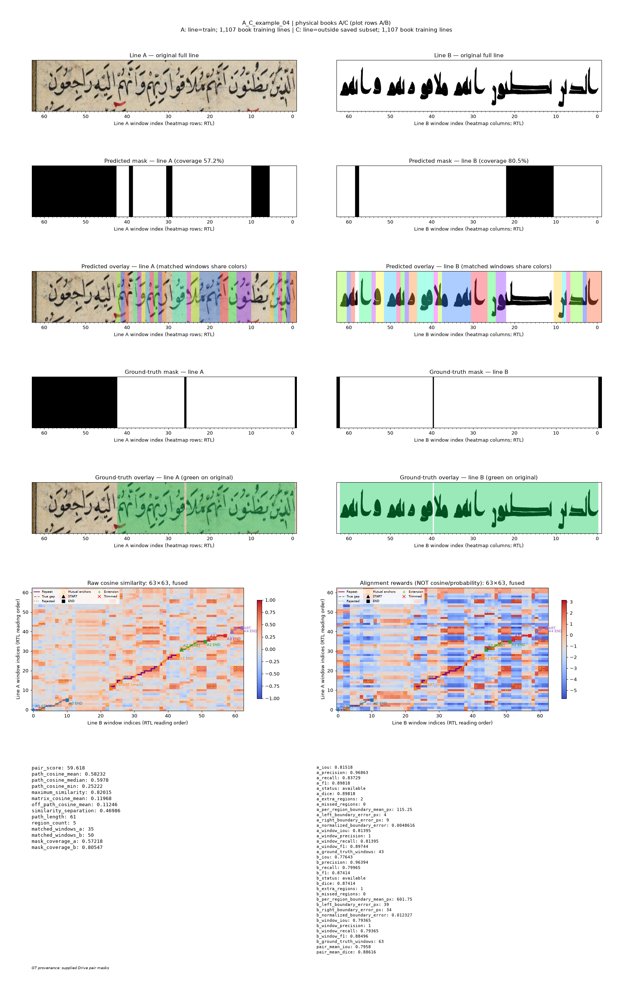

In [ ]:
from IPython.display import Image, display
print('A_C_example_04 | physical books A/C (plot rows A/B)\nA: line=train; 1,107 book training lines | C: line=outside saved subset; 1,107 book training lines\nIoU: A=0.815, C=0.776; accepted routes=5\nMean mask IoU=0.796\nWhite-mask precision: A=0.969, C=0.964; recall: A=0.837, C=0.800\nPredicted white coverage: A=57.2%, C=80.5%\nBlack-background specificity: A=0.947, C=0.000\nWhite F2 (recall priority): A=0.861, C=0.828')
display(Image(filename=str(REVIEW / 'A_C_example_04.png')))


A_C_example_05 | physical books A/C (plot rows A/B)
A: line=train; 1,107 book training lines | C: line=outside saved subset; 1,107 book training lines
IoU: A=0.747, C=0.544; accepted routes=5
Mean mask IoU=0.645
White-mask precision: A=1.000, C=0.807; recall: A=0.747, C=0.625
Predicted white coverage: A=39.1%, C=61.0%
Black-background specificity: A=1.000, C=0.443
White F2 (recall priority): A=0.787, C=0.654


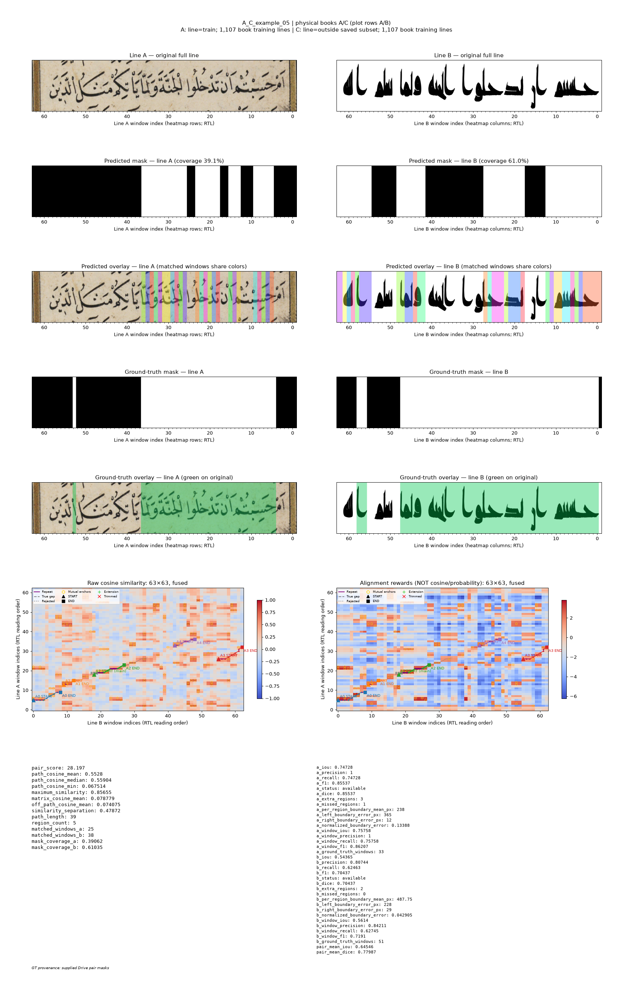

In [ ]:
from IPython.display import Image, display
print('A_C_example_05 | physical books A/C (plot rows A/B)\nA: line=train; 1,107 book training lines | C: line=outside saved subset; 1,107 book training lines\nIoU: A=0.747, C=0.544; accepted routes=5\nMean mask IoU=0.645\nWhite-mask precision: A=1.000, C=0.807; recall: A=0.747, C=0.625\nPredicted white coverage: A=39.1%, C=61.0%\nBlack-background specificity: A=1.000, C=0.443\nWhite F2 (recall priority): A=0.787, C=0.654')
display(Image(filename=str(REVIEW / 'A_C_example_05.png')))


B_C_example_01 | physical books B/C (plot rows A/B)
B: line=train; 1,107 book training lines | C: line=outside saved subset; 1,107 book training lines
IoU: B=0.945, C=0.936; accepted routes=1
Mean mask IoU=0.941
White-mask precision: B=0.945, C=0.936; recall: B=1.000, C=1.000
Predicted white coverage: B=54.8%, C=79.7%
Black-background specificity: B=0.938, C=0.799
White F2 (recall priority): B=0.989, C=0.986


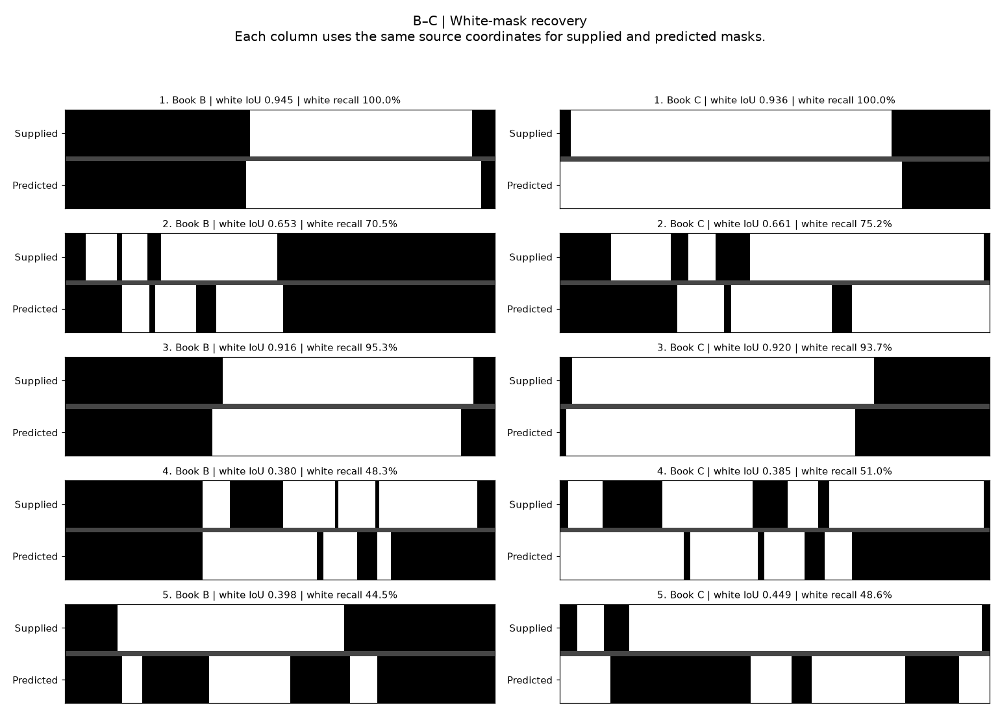

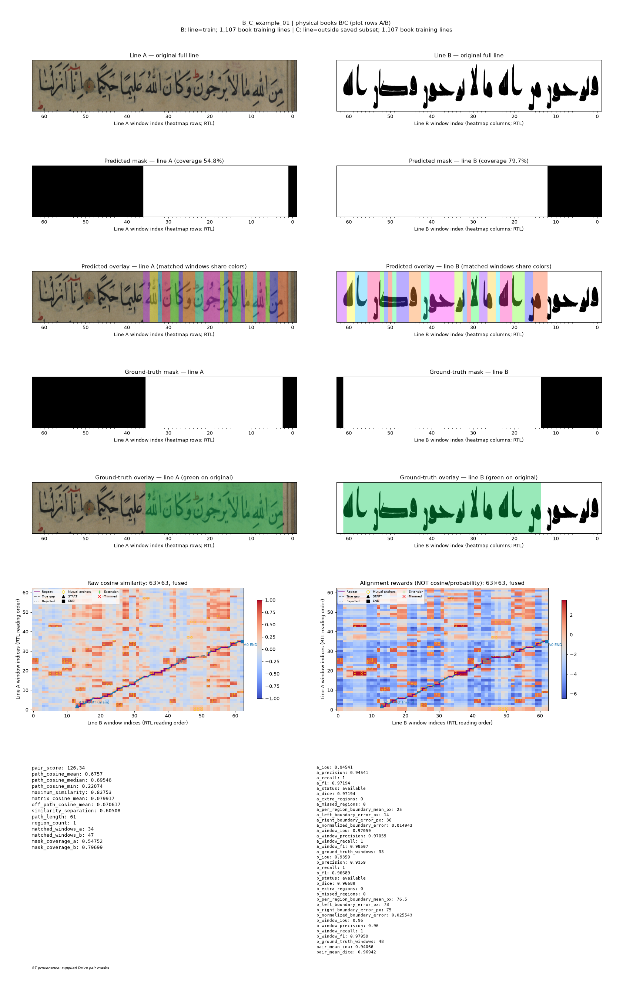

In [ ]:
from IPython.display import Image, display
print('B_C_example_01 | physical books B/C (plot rows A/B)\nB: line=train; 1,107 book training lines | C: line=outside saved subset; 1,107 book training lines\nIoU: B=0.945, C=0.936; accepted routes=1\nMean mask IoU=0.941\nWhite-mask precision: B=0.945, C=0.936; recall: B=1.000, C=1.000\nPredicted white coverage: B=54.8%, C=79.7%\nBlack-background specificity: B=0.938, C=0.799\nWhite F2 (recall priority): B=0.989, C=0.986')
display(Image(filename=str(REVIEW / 'white_masks_B_C.png')))
display(Image(filename=str(REVIEW / 'B_C_example_01.png')))


B_C_example_02 | physical books B/C (plot rows A/B)
B: line=train; 1,107 book training lines | C: line=outside saved subset; 1,107 book training lines
IoU: B=0.653, C=0.661; accepted routes=4
Mean mask IoU=0.657
White-mask precision: B=0.898, C=0.844; recall: B=0.705, C=0.752
Predicted white coverage: B=31.5%, C=66.5%
Black-background specificity: B=0.946, C=0.592
White F2 (recall priority): B=0.737, C=0.769


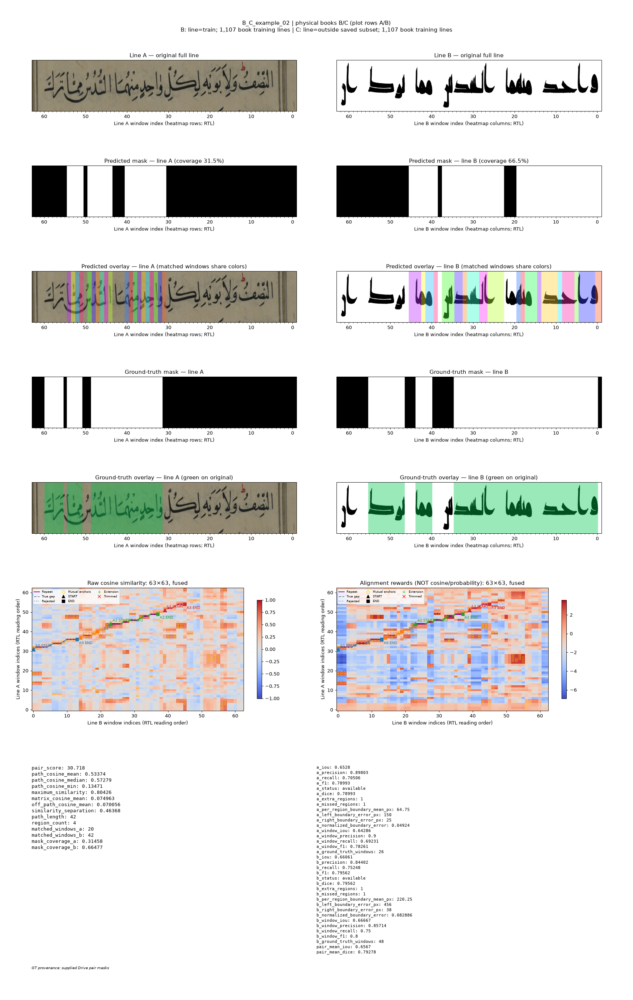

In [ ]:
from IPython.display import Image, display
print('B_C_example_02 | physical books B/C (plot rows A/B)\nB: line=train; 1,107 book training lines | C: line=outside saved subset; 1,107 book training lines\nIoU: B=0.653, C=0.661; accepted routes=4\nMean mask IoU=0.657\nWhite-mask precision: B=0.898, C=0.844; recall: B=0.705, C=0.752\nPredicted white coverage: B=31.5%, C=66.5%\nBlack-background specificity: B=0.946, C=0.592\nWhite F2 (recall priority): B=0.737, C=0.769')
display(Image(filename=str(REVIEW / 'B_C_example_02.png')))


B_C_example_03 | physical books B/C (plot rows A/B)
B: line=train; 1,107 book training lines | C: line=train; 1,107 book training lines
IoU: B=0.916, C=0.920; accepted routes=1
Mean mask IoU=0.918
White-mask precision: B=0.960, C=0.980; recall: B=0.953, C=0.937
Predicted white coverage: B=57.9%, C=67.2%
Black-background specificity: B=0.944, C=0.956
White F2 (recall priority): B=0.954, C=0.945


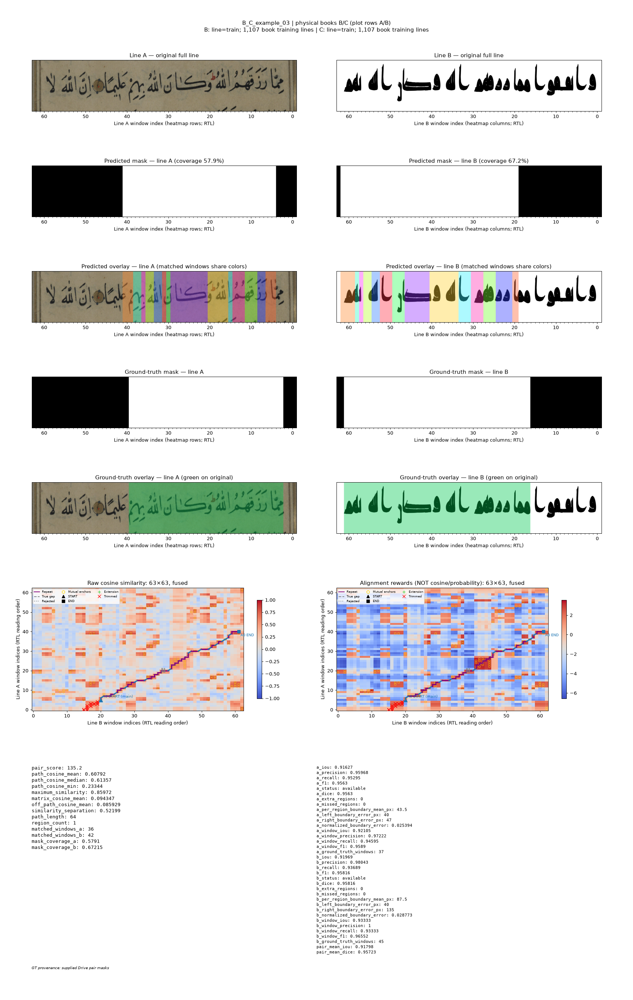

In [ ]:
from IPython.display import Image, display
print('B_C_example_03 | physical books B/C (plot rows A/B)\nB: line=train; 1,107 book training lines | C: line=train; 1,107 book training lines\nIoU: B=0.916, C=0.920; accepted routes=1\nMean mask IoU=0.918\nWhite-mask precision: B=0.960, C=0.980; recall: B=0.953, C=0.937\nPredicted white coverage: B=57.9%, C=67.2%\nBlack-background specificity: B=0.944, C=0.956\nWhite F2 (recall priority): B=0.954, C=0.945')
display(Image(filename=str(REVIEW / 'B_C_example_03.png')))


B_C_example_04 | physical books B/C (plot rows A/B)
B: line=train; 1,107 book training lines | C: line=outside saved subset; 1,107 book training lines
IoU: B=0.380, C=0.385; accepted routes=6
Mean mask IoU=0.383
White-mask precision: B=0.641, C=0.611; recall: B=0.483, C=0.510
Predicted white coverage: B=37.7%, C=60.3%
Black-background specificity: B=0.730, C=0.157
White F2 (recall priority): B=0.508, C=0.527


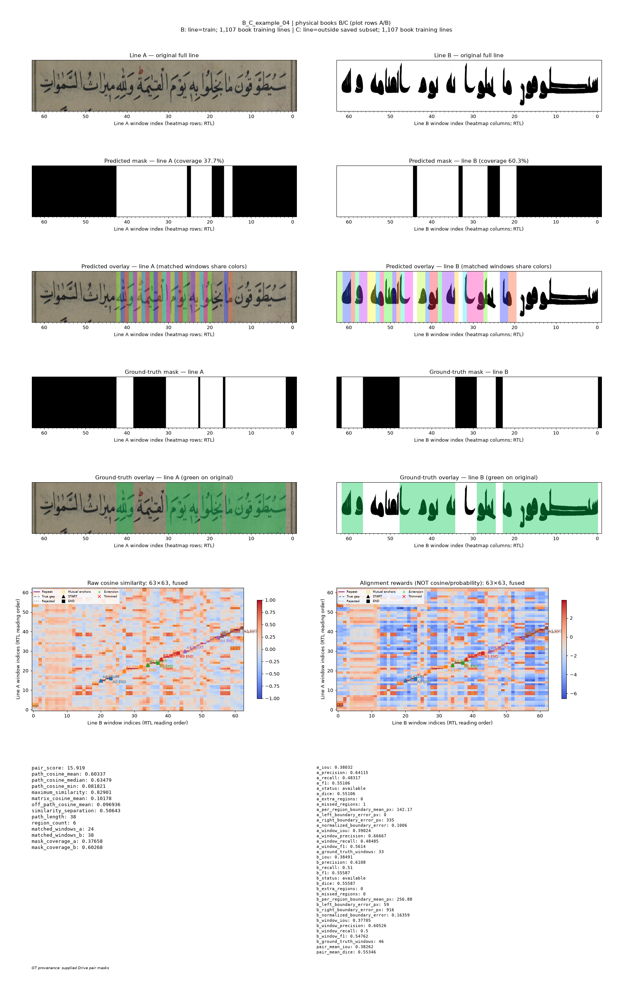

In [ ]:
from IPython.display import Image, display
print('B_C_example_04 | physical books B/C (plot rows A/B)\nB: line=train; 1,107 book training lines | C: line=outside saved subset; 1,107 book training lines\nIoU: B=0.380, C=0.385; accepted routes=6\nMean mask IoU=0.383\nWhite-mask precision: B=0.641, C=0.611; recall: B=0.483, C=0.510\nPredicted white coverage: B=37.7%, C=60.3%\nBlack-background specificity: B=0.730, C=0.157\nWhite F2 (recall priority): B=0.508, C=0.527')
display(Image(filename=str(REVIEW / 'B_C_example_04.png')))


B_C_example_05 | physical books B/C (plot rows A/B)
B: line=train; 1,107 book training lines | C: line=test; 1,107 book training lines
IoU: B=0.398, C=0.449; accepted routes=4
Mean mask IoU=0.424
White-mask precision: B=0.789, C=0.856; recall: B=0.445, C=0.486
Predicted white coverage: B=29.8%, C=50.1%
Black-background specificity: B=0.866, C=0.385
White F2 (recall priority): B=0.488, C=0.532


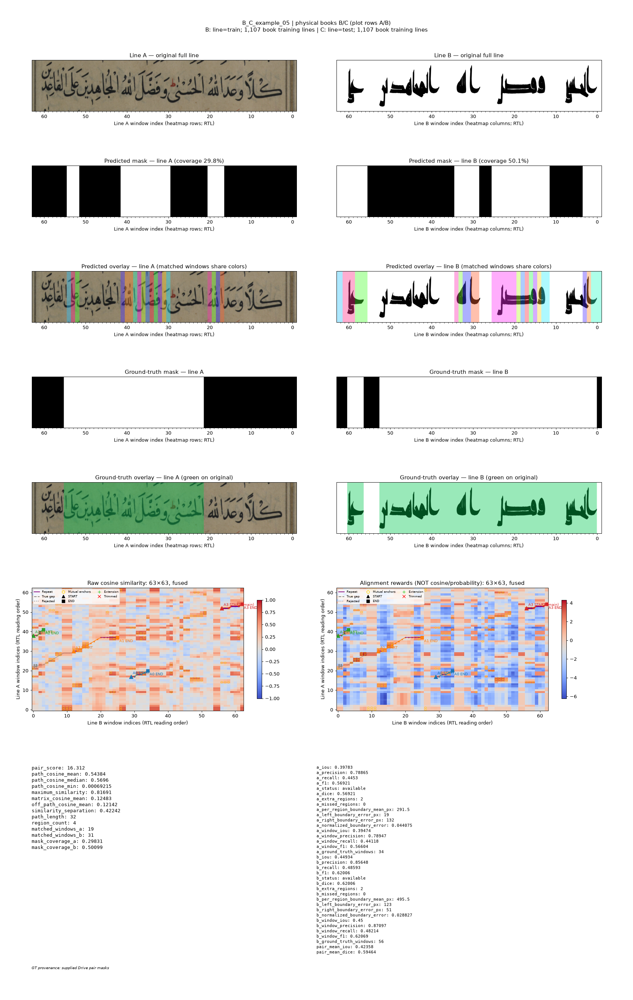

In [ ]:
from IPython.display import Image, display
print('B_C_example_05 | physical books B/C (plot rows A/B)\nB: line=train; 1,107 book training lines | C: line=test; 1,107 book training lines\nIoU: B=0.398, C=0.449; accepted routes=4\nMean mask IoU=0.424\nWhite-mask precision: B=0.789, C=0.856; recall: B=0.445, C=0.486\nPredicted white coverage: B=29.8%, C=50.1%\nBlack-background specificity: B=0.866, C=0.385\nWhite F2 (recall priority): B=0.488, C=0.532')
display(Image(filename=str(REVIEW / 'B_C_example_05.png')))
